# IFN680 Project 8 — Extending Tiny NeRF
## main_report.ipynb — Task 3: Comparative analysis and evaluation

This notebook reproduces **all** numerical results and plots reported for Task 3.
It contains **no training loop**: both models are rebuilt from their class definitions and
restored from the saved weights produced by `TinyNeRF.ipynb` and `ExtendedNeRF.ipynb`.

**Required files in the same folder**

| File | Produced by |
|---|---|
| `tiny_nerf_data.npz` | provided dataset |
| `tiny.pth`, `psnrs_tiny.pkl` | `TinyNeRF.ipynb` |
| `extended_coarse.pth`, `extended_fine.pth`, `psnrs_extended.pkl` | `ExtendedNeRF.ipynb` |

**Models compared**

| | Tiny NeRF (baseline) | Extended NeRF |
|---|---|---|
| Colour | position only (matte) | position + **view direction** (Task 1) |
| Sampling | uniform, 64 samples | **hierarchical**, 32 coarse + 64 importance (Task 2) |
| Networks | 1 | 2 (coarse + fine) |
| Training | 100 epochs, Adam lr 5e-4, seed 1337 | 100 epochs, Adam lr 5e-4, seed 1337 |

## 1. Setup

In [1]:
# Imports and device
import os
import pickle
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Fixed seed: evaluation uses rand=False everywhere, but we set it for full determinism
torch.manual_seed(1337)
np.random.seed(1337)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
print(f"PyTorch version: {torch.__version__}")

Using device: cuda
PyTorch version: 2.13.0+cu126


## 2. Dataset and train / test split

Identical to the split used during training: the last 6 views are held out and were never seen by either model.

In [2]:
# Load the dataset and rebuild the exact split used for training
data = np.load('tiny_nerf_data.npz')
images = torch.from_numpy(data['images']).float().to(device)
poses = torch.from_numpy(data['poses']).float().to(device)
focal = float(data['focal'])
H, W = images.shape[1:3]
K = torch.Tensor([[focal, 0, W/2.0], [0, focal, H/2.0], [0, 0, 1]]).float().to(device)

test_images, test_poses = images[100:], poses[100:]
train_images, train_poses = images[:100], poses[:100]

print(f"images {tuple(images.shape)} | focal {focal:.4f} | H,W = {H},{W}")
print(f"train split: {tuple(train_images.shape)} | test split (held out): {tuple(test_images.shape)}")

images (106, 100, 100, 3) | focal 138.8889 | H,W = 100,100
train split: (100, 100, 100, 3) | test split (held out): (6, 100, 100, 3)


## 3. Model and rendering code

The class definitions and rendering functions are copied verbatim from `TinyNeRF.ipynb` and `ExtendedNeRF.ipynb` so the saved weights load into exactly the architecture they were trained with.

In [3]:
def get_rays(K, c2w, H, W):
    """
    Get ray origin and direction for each image pixel based on the camera pose.
    """
    # 1. Create pixel grid, x first
    i, j = torch.meshgrid(
        torch.arange(W, dtype=torch.float32, device=c2w.device),
        torch.arange(H, dtype=torch.float32, device=c2w.device),
        indexing='xy'
    )

    # 2. Get directions in camera coordinates
    dirs = torch.stack([
        (i - K[0, 2]) / K[0, 0],
        -(j - K[1, 2]) / K[1, 1],
        -torch.ones_like(i)
    ], dim=-1)

    # 3. Transform directions to world space
    rays_d = dirs @ c2w[:3, :3].T

    # 4. Origin is the translation vector of the camera-to-world matrix
    rays_o = c2w[:3, -1].expand(rays_d.shape)

    return rays_o, rays_d

In [4]:
class PositionalEncoding(torch.nn.Module):
    """
    Positional encoding module
    """
    def __init__(self, L_embed=6):
        super(PositionalEncoding, self).__init__()
        self.L_embed = L_embed
        self.bands = (2.0 ** torch.arange(L_embed, dtype=torch.float32).to(device)) * torch.pi
        self.bands = self.bands.view(1, L_embed, 1)

    def forward(self, x):
        x_scaled = x.unsqueeze(-2) * self.bands
        sin_cos = torch.cat([torch.sin(x_scaled), torch.cos(x_scaled)], dim=-2)
        sin_cos = sin_cos.flatten(start_dim=-2)
        encoded = torch.cat([x, sin_cos], dim=-1)
        return encoded


class TinyNeRF(torch.nn.Module):
    """
    Baseline NeRF MLP from Tutorial 10.4: 3 layers, no view-dependence.
    Colour and density are both predicted from position only.
    """
    def __init__(self, filter_size=128, L_embed=6):
        super(TinyNeRF, self).__init__()
        self.positional_encoding = PositionalEncoding(L_embed)
        self.layer1 = torch.nn.Linear(3 + 3*2*L_embed, filter_size)
        self.layer2 = torch.nn.Linear(filter_size, filter_size)
        self.layer3 = torch.nn.Linear(filter_size, 4)
        self.relu = torch.nn.functional.relu

    def forward(self, x):
        x = self.positional_encoding(x)
        x = self.relu(self.layer1(x))
        x = self.relu(self.layer2(x))
        x = self.layer3(x)

        sigma = self.relu(x[..., [0]])
        rgb = torch.sigmoid(x[..., 1:])
        return torch.cat([sigma, rgb], dim=-1)


class ExtendedNeRF(torch.nn.Module):
    """
    TASK 1 - NeRF MLP with view-direction dependency.
    Density depends on position only; colour depends on position features + view direction.
    """
    def __init__(self, filter_size=128, L_embed=6, L_dir=4):
        super(ExtendedNeRF, self).__init__()
        self.positional_encoding = PositionalEncoding(L_embed)
        self.direction_encoding = PositionalEncoding(L_dir)

        x_dim = 3 + 3 * 2 * L_embed
        d_dim = 3 + 3 * 2 * L_dir

        # Position trunk
        self.layer1 = torch.nn.Linear(x_dim, filter_size)
        self.layer2 = torch.nn.Linear(filter_size, filter_size)

        # Density
        self.sigma_layer = torch.nn.Linear(filter_size, 1)
        # geometric features
        self.feature_layer = torch.nn.Linear(filter_size, filter_size)

        # Colour head conditioned on view direction
        self.color_layer1 = torch.nn.Linear(filter_size + d_dim, filter_size // 2)
        self.color_layer2 = torch.nn.Linear(filter_size // 2, 3)

    def forward(self, x, dir):
        # Encode position and view direction with their own frequency bands
        x_enc = self.positional_encoding(x)
        d_enc = self.direction_encoding(dir)

        # Position trunk: position -> hidden features
        h = F.relu(self.layer1(x_enc))
        h = F.relu(self.layer2(h))

        # Density head: depends on POSITION ONLY (keeps geometry view-consistent)
        sigma = F.relu(self.sigma_layer(h))

        # Geometric feature vector handed to the colour head
        feature = self.feature_layer(h)

        # Colour head: geometric feature + encoded view direction
        h_c = F.relu(self.color_layer1(torch.cat([feature, d_enc], dim=-1)))
        rgb = torch.sigmoid(self.color_layer2(h_c))

        return torch.cat([sigma, rgb], dim=-1)

print(TinyNeRF(), "\n")
print(ExtendedNeRF())

TinyNeRF(
  (positional_encoding): PositionalEncoding()
  (layer1): Linear(in_features=39, out_features=128, bias=True)
  (layer2): Linear(in_features=128, out_features=128, bias=True)
  (layer3): Linear(in_features=128, out_features=4, bias=True)
) 

ExtendedNeRF(
  (positional_encoding): PositionalEncoding()
  (direction_encoding): PositionalEncoding()
  (layer1): Linear(in_features=39, out_features=128, bias=True)
  (layer2): Linear(in_features=128, out_features=128, bias=True)
  (sigma_layer): Linear(in_features=128, out_features=1, bias=True)
  (feature_layer): Linear(in_features=128, out_features=128, bias=True)
  (color_layer1): Linear(in_features=155, out_features=64, bias=True)
  (color_layer2): Linear(in_features=64, out_features=3, bias=True)
)


In [5]:
def volume_rendering(sigma, rgb, t_vals):
    # Calculate distance between samples (delta)
    deltas = t_vals[..., 1:] - t_vals[..., :-1]

    # Append a large value (1e10) for the last interval
    dist_shape = list(deltas.shape[:-1]) + [1]
    last_dist = torch.full(dist_shape, 1e10, device=sigma.device)
    deltas = torch.cat([deltas, last_dist], dim=-1)

    # alpha = 1.0 - exp(-sigma * delta)
    alpha = 1.0 - torch.exp(-sigma * deltas)

    # Transmittance T_i = product of (1 - alpha_j) for j < i
    shifted_transmittance = torch.cat([torch.ones_like(alpha[..., :1]), 1.0 - alpha + 1e-10], dim=-1)
    T = torch.cumprod(shifted_transmittance, dim=-1)[..., :-1]

    # colour blending
    weights = alpha * T
    rgb_map = torch.sum(weights[..., None] * rgb, dim=-2)

    return rgb_map, weights


def sample_pdf(bins, weights, N_samples, rand=False):
    # Get PDF and CDF from weights
    weights = weights + 1e-5
    pdf = weights / torch.sum(weights, dim=-1, keepdim=True)
    cdf = torch.cumsum(pdf, dim=-1)
    cdf = torch.cat([torch.zeros_like(cdf[..., :1]), cdf], dim=-1)

    # Sample uniform points u
    if rand:
        u = torch.rand(list(cdf.shape[:-1]) + [N_samples], device=cdf.device)
    else:
        u = torch.linspace(0., 1., steps=N_samples, device=cdf.device)
        u = u.expand(list(cdf.shape[:-1]) + [N_samples])

    u = u.contiguous()

    # Find indices where u fits in the CDF
    inds = torch.searchsorted(cdf, u, right=True)
    below = torch.max(torch.zeros_like(inds - 1), inds - 1)
    above = torch.min((cdf.shape[-1] - 1) * torch.ones_like(inds), inds)

    cdf_g0 = torch.gather(cdf, -1, below)
    cdf_g1 = torch.gather(cdf, -1, above)
    bins_g0 = torch.gather(bins, -1, below)
    bins_g1 = torch.gather(bins, -1, above)

    # Linear interpolation
    denom = (cdf_g1 - cdf_g0)
    denom = torch.where(denom < 1e-5, torch.ones_like(denom), denom)
    t = (u - cdf_g0) / denom
    samples = bins_g0 + t * (bins_g1 - bins_g0)

    return samples

In [6]:
def render_rays_tiny(network, rays_o, rays_d, near, far, num_samples, rand=False):
    """
    Baseline renderer from Tutorial 10.4: uniform (stratified) sampling, one network.
    """
    z_vals = torch.linspace(near, far, num_samples, device=rays_o.device)
    z_vals = z_vals.expand(list(rays_o.shape[:-1]) + [num_samples])

    if rand:
        bin_edges = torch.linspace(near, far, num_samples + 1, device=rays_o.device)
        lower = bin_edges[:-1]; widths = bin_edges[1:] - lower
        z_vals = lower + torch.rand_like(z_vals) * widths

    # Points in space: r(t) = o + td
    pts = rays_o[..., None, :] + z_vals[..., :, None] * rays_d[..., None, :]

    raw = network(pts.reshape(-1, 3))
    raw = raw.view(list(pts.shape[:-1]) + [4])
    sigma, rgb = raw[..., 0], raw[..., 1:]

    rgb_map, _ = volume_rendering(sigma, rgb, z_vals)
    return rgb_map


def render_rays_extended(coarse_network, fine_network, rays_o, rays_d, near, far,
                         N_c, N_f, rand=False, dir_override=None):
    """
    TASK 2 - hierarchical sampling with a coarse and a fine network.

    dir_override: evaluation-only argument used in section 7 to feed the colour head a
    viewing direction other than the true one, isolating the view-dependent component.
    It is None for every result reported in Tasks 1-3.
    """
    # 1. Stratified Sampling (Coarse)
    z_vals = torch.linspace(near, far, N_c, device=rays_o.device)
    z_vals = z_vals.expand(list(rays_o.shape[:-1]) + [N_c])

    if rand:
        bin_edges = torch.linspace(near, far, N_c + 1, device=rays_o.device)
        lower = bin_edges[:-1]; widths = bin_edges[1:] - lower
        z_vals = lower + torch.rand_like(z_vals) * widths

    # Points in space: r(t) = o + td
    pts_c = rays_o[..., None, :] + z_vals[..., :, None] * rays_d[..., None, :]

    # View direction: unit vector, shared by every sample along the same ray
    viewdirs = rays_d / torch.norm(rays_d, dim=-1, keepdim=True)
    if dir_override is not None:
        viewdirs = dir_override.view(1, 3).expand_as(viewdirs)
    dirs_c = viewdirs[..., None, :].expand(pts_c.shape)

    # Coarse pass
    raw_c = coarse_network(pts_c.reshape(-1, 3), dirs_c.reshape(-1, 3))
    raw_c = raw_c.view(list(pts_c.shape[:-1]) + [4])
    sigma_c, rgb_c = raw_c[..., 0], raw_c[..., 1:]
    rgb_map_c, weights_c = volume_rendering(sigma_c, rgb_c, z_vals)

    # 2. Hierarchical Sampling (Fine)
    z_mid = 0.5 * (z_vals[..., 1:] + z_vals[..., :-1])
    z_samples = sample_pdf(z_mid, weights_c[..., 1:-1], N_f, rand=rand)
    z_samples = z_samples.detach()

    # Combine and sort all samples
    z_vals_f, _ = torch.sort(torch.cat([z_vals, z_samples], dim=-1), dim=-1)
    pts_f = rays_o[..., None, :] + z_vals_f[..., :, None] * rays_d[..., None, :]
    dirs_f = viewdirs[..., None, :].expand(pts_f.shape)

    # Fine pass
    raw_f = fine_network(pts_f.reshape(-1, 3), dirs_f.reshape(-1, 3))
    raw_f = raw_f.view(list(pts_f.shape[:-1]) + [4])
    sigma_f, rgb_f = raw_f[..., 0], raw_f[..., 1:]
    rgb_map_f, _ = volume_rendering(sigma_f, rgb_f, z_vals_f)

    return rgb_map_c, rgb_map_f

## 4. Restore the trained weights

No training happens in this notebook — the weights are loaded from the `.pth` files.

In [7]:
# Rendering hyperparameters, identical to the ones used at training time
N_SAMPLES = 64          # Tiny NeRF: uniform samples per ray
N_C, N_F = 32, 64       # Extended NeRF: coarse samples, importance samples
NEAR, FAR = 2., 6.

# Baseline
tiny = TinyNeRF(filter_size=128, L_embed=6).to(device)
tiny.load_state_dict(torch.load('tiny.pth', map_location=device))
tiny.eval()

# Extended (coarse + fine)
ext_coarse = ExtendedNeRF(filter_size=128, L_embed=6).to(device)
ext_fine   = ExtendedNeRF(filter_size=128, L_embed=6).to(device)
ext_coarse.load_state_dict(torch.load('extended_coarse.pth', map_location=device))
ext_fine.load_state_dict(torch.load('extended_fine.pth', map_location=device))
ext_coarse.eval(); ext_fine.eval()

n_tiny = sum(p.numel() for p in tiny.parameters())
n_ext  = sum(p.numel() for p in ext_coarse.parameters()) + sum(p.numel() for p in ext_fine.parameters())
print(f"Tiny NeRF     : {n_tiny:,} parameters (1 network)")
print(f"Extended NeRF : {n_ext:,} parameters (2 networks)")
print("All weights loaded; both models set to eval() mode.")

Tiny NeRF     : 22,148 parameters (1 network)
Extended NeRF : 96,904 parameters (2 networks)
All weights loaded; both models set to eval() mode.


### Chunked rendering

A full 100x100 view is 10,000 rays x 96 samples = 960,000 network queries, whose intermediate
activations need roughly 0.5 GB per layer. The IFN680 GPU is shared, so rays are rendered in
small batches instead of all at once. Rendering is deterministic (`rand=False`) and rays do not
interact, so chunking changes nothing in the result - only the peak memory.

If a cell still runs out of memory on your machine, lower `RAY_CHUNK`.

In [8]:
RAY_CHUNK = 1024   # rays rendered per batch; lower this if the GPU runs out of memory

@torch.no_grad()
def render_image_tiny(rays_o, rays_d):
    """
    Render one full image with the baseline model, one RAY_CHUNK of rays at a time.
    rays_o, rays_d: [H, W, 3]  ->  returns [H, W, 3]
    """
    o, d = rays_o.reshape(-1, 3), rays_d.reshape(-1, 3)
    chunks = []
    for i in range(0, o.shape[0], RAY_CHUNK):
        chunks.append(render_rays_tiny(tiny, o[i:i+RAY_CHUNK], d[i:i+RAY_CHUNK],
                                       NEAR, FAR, N_SAMPLES, rand=False))
    return torch.cat(chunks, dim=0).view(rays_o.shape)


@torch.no_grad()
def render_image_extended(rays_o, rays_d, dir_override=None):
    """
    Render one full image with the extended model (fine output), chunked the same way.
    """
    o, d = rays_o.reshape(-1, 3), rays_d.reshape(-1, 3)
    chunks = []
    for i in range(0, o.shape[0], RAY_CHUNK):
        _, rgb = render_rays_extended(ext_coarse, ext_fine, o[i:i+RAY_CHUNK], d[i:i+RAY_CHUNK],
                                      NEAR, FAR, N_C, N_F, rand=False, dir_override=dir_override)
        chunks.append(rgb)
    return torch.cat(chunks, dim=0).view(rays_o.shape)


if device.type == 'cuda':
    torch.cuda.empty_cache()
    free_b, total_b = torch.cuda.mem_get_info()
    print(f"GPU memory free: {free_b/2**30:.2f} GiB of {total_b/2**30:.2f} GiB")
print(f"Rendering {RAY_CHUNK} rays per batch "
      f"({(H*W + RAY_CHUNK - 1)//RAY_CHUNK} batches per 100x100 view)")

GPU memory free: 3.31 GiB of 3.83 GiB
Rendering 1024 rays per batch (10 batches per 100x100 view)


## 5. Quantitative evaluation — PSNR on the held-out test views

PSNR is computed exactly as during training, `PSNR = -10 log10(MSE)`, on the 6 test views
that neither model saw. Rendering uses `rand=False` so the result is deterministic.

In [9]:
@torch.no_grad()
def render_test_views():
    """
    Render all 6 held-out test views with both models.
    Returns: dict of name -> (list of images [H,W,3], list of PSNRs)
    """
    out = {'Tiny NeRF': ([], []), 'Extended NeRF': ([], [])}
    for i in range(len(test_images)):
        rays_o, rays_d = get_rays(K, test_poses[i], H, W)

        rgb_t = render_image_tiny(rays_o, rays_d)
        rgb_e = render_image_extended(rays_o, rays_d)

        for name, rgb in [('Tiny NeRF', rgb_t), ('Extended NeRF', rgb_e)]:
            mse = F.mse_loss(rgb, test_images[i])
            psnr = (-10. * torch.log10(mse)).item()
            out[name][0].append(rgb.clamp(0, 1).cpu().numpy())
            out[name][1].append(psnr)
    return out

results = render_test_views()
psnr_tiny = results['Tiny NeRF'][1]
psnr_ext  = results['Extended NeRF'][1]

# Results table
print(f"{'Test view':<12}{'Tiny NeRF':>12}{'Extended':>12}{'Gain (dB)':>12}")
print("-" * 48)
for i in range(len(test_images)):
    print(f"{i:<12}{psnr_tiny[i]:>12.2f}{psnr_ext[i]:>12.2f}{psnr_ext[i]-psnr_tiny[i]:>12.2f}")
print("-" * 48)
print(f"{'Mean':<12}{np.mean(psnr_tiny):>12.2f}{np.mean(psnr_ext):>12.2f}"
      f"{np.mean(psnr_ext)-np.mean(psnr_tiny):>12.2f}")
print(f"{'Std':<12}{np.std(psnr_tiny, ddof=1):>12.2f}{np.std(psnr_ext, ddof=1):>12.2f}")
print()
print(f"Target from the project brief: 28 dB average on the test set")
print(f"Extended NeRF achieved       : {np.mean(psnr_ext):.2f} dB "
      f"-> {'PASS' if np.mean(psnr_ext) >= 28 else 'BELOW TARGET'}")

Test view      Tiny NeRF    Extended   Gain (dB)
------------------------------------------------
0                  24.20       26.83        2.64
1                  24.89       28.50        3.61
2                  25.26       29.48        4.22
3                  26.50       30.02        3.52
4                  27.08       29.92        2.84
5                  26.18       30.28        4.10
------------------------------------------------
Mean               25.68       29.17        3.49
Std                 1.09        1.31

Target from the project brief: 28 dB average on the test set
Extended NeRF achieved       : 29.17 dB -> PASS


### Paired significance check

With only 6 test views a t-test is weak, but the comparison is **paired** (both models are
evaluated on exactly the same views), so the per-view differences are the informative quantity.

In [10]:
diffs = np.array(psnr_ext) - np.array(psnr_tiny)
print("per-view PSNR gain (dB):", np.round(diffs, 2))
print(f"mean gain {diffs.mean():.2f} dB | min {diffs.min():.2f} | max {diffs.max():.2f}")
print(f"Extended NeRF wins on {int((diffs > 0).sum())}/{len(diffs)} test views")

per-view PSNR gain (dB): [2.64 3.61 4.22 3.52 2.84 4.1 ]
mean gain 3.49 dB | min 2.64 | max 4.22
Extended NeRF wins on 6/6 test views


## 6. Training curves

Average **training** PSNR per epoch for both models, recorded during training and reloaded from
the saved `.pkl` files.

> *Note on the data available:* the per-epoch **test** curve was retained for the Tiny NeRF run
> but not for the Extended NeRF run. The Extended NeRF test figures reported in section 5 are
> therefore computed directly from the saved weights rather than read from a stored curve, which
> is the more reliable source in any case.

Tiny     -> train: 100 epochs | test: 100
Extended -> train: 100 epochs | test: 100


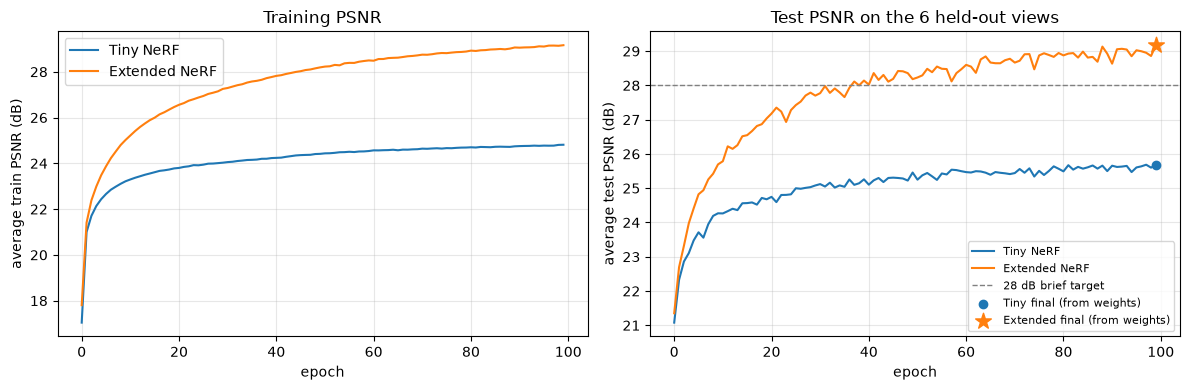

In [11]:
with open('psnrs_tiny.pkl', 'rb') as f:
    curves_tiny = pickle.load(f)
with open('psnrs_extended.pkl', 'rb') as f:
    curves_ext = pickle.load(f)

print('Tiny     -> train:', len(curves_tiny['train']), 'epochs | test:', len(curves_tiny['test']))
print('Extended -> train:', len(curves_ext['train']),  'epochs | test:', len(curves_ext['test']))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(curves_tiny['train'], label='Tiny NeRF')
axes[0].plot(curves_ext['train'],  label='Extended NeRF')
axes[0].set_xlabel('epoch'); axes[0].set_ylabel('average train PSNR (dB)')
axes[0].set_title('Training PSNR'); axes[0].legend(); axes[0].grid(alpha=.3)

if len(curves_tiny['test']):
    axes[1].plot(curves_tiny['test'], label='Tiny NeRF')
if len(curves_ext['test']):
    axes[1].plot(curves_ext['test'], label='Extended NeRF')
axes[1].axhline(28, ls='--', c='grey', lw=1, label='28 dB brief target')
axes[1].scatter([len(curves_tiny['train'])-1], [np.mean(psnr_tiny)], marker='o', zorder=5,
                label='Tiny final (from weights)')
axes[1].scatter([len(curves_ext['train'])-1], [np.mean(psnr_ext)], marker='*', s=140, zorder=5,
                label='Extended final (from weights)')
axes[1].set_xlabel('epoch'); axes[1].set_ylabel('average test PSNR (dB)')
axes[1].set_title('Test PSNR on the 6 held-out views'); axes[1].legend(fontsize=8); axes[1].grid(alpha=.3)

plt.tight_layout(); plt.show()

## 7. Qualitative comparison — held-out test views

Ground truth, Tiny NeRF and Extended NeRF side by side for all 6 test views.

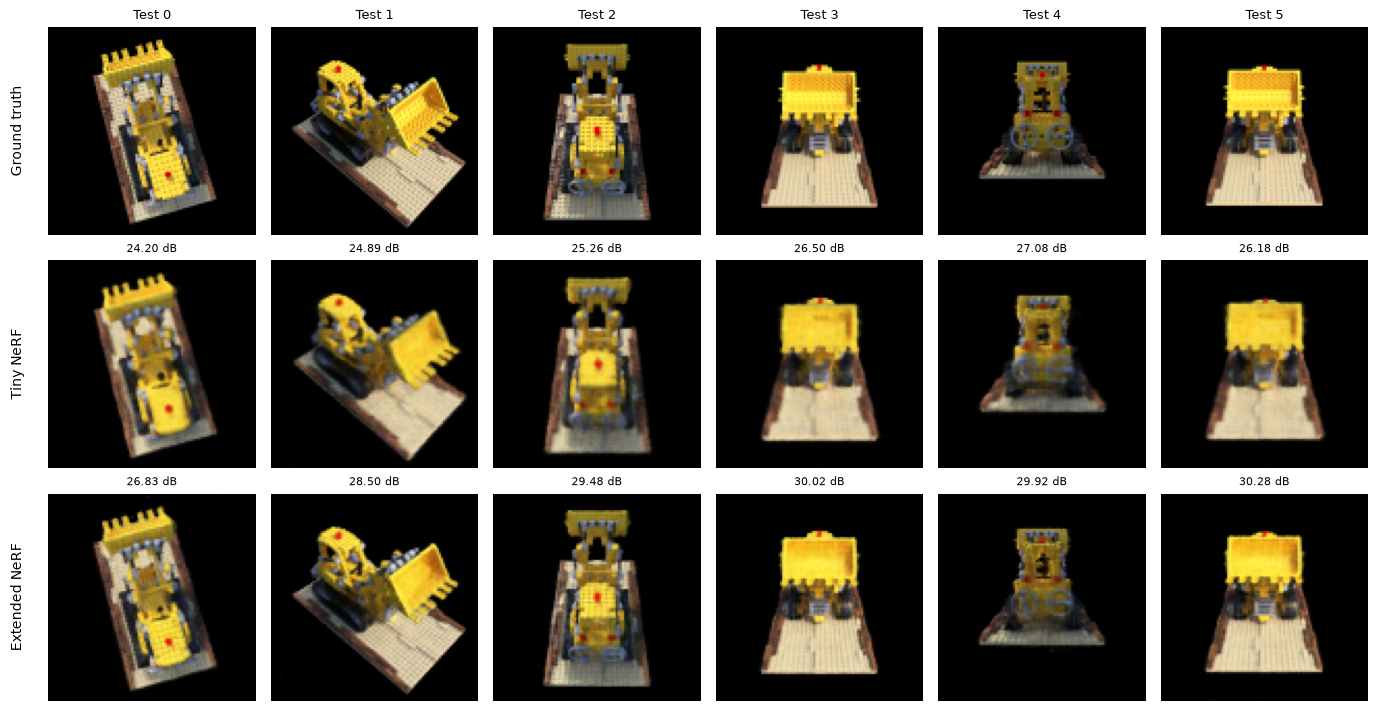

In [12]:
fig, axes = plt.subplots(3, len(test_images), figsize=(2.3*len(test_images), 7.2))
for i in range(len(test_images)):
    axes[0, i].imshow(test_images[i].cpu().numpy())
    axes[0, i].set_title(f'Test {i}', fontsize=9)
    axes[1, i].imshow(results['Tiny NeRF'][0][i])
    axes[1, i].set_title(f'{psnr_tiny[i]:.2f} dB', fontsize=8)
    axes[2, i].imshow(results['Extended NeRF'][0][i])
    axes[2, i].set_title(f'{psnr_ext[i]:.2f} dB', fontsize=8)
    for r in range(3):
        axes[r, i].axis('off')

for r, label in enumerate(['Ground truth', 'Tiny NeRF', 'Extended NeRF']):
    axes[r, 0].text(-0.15, 0.5, label, transform=axes[r, 0].transAxes,
                    rotation=90, va='center', ha='center', fontsize=10)

plt.tight_layout(); plt.show()

### Absolute error maps

Brighter pixels mean larger error against the ground truth. Both maps use the same colour scale.

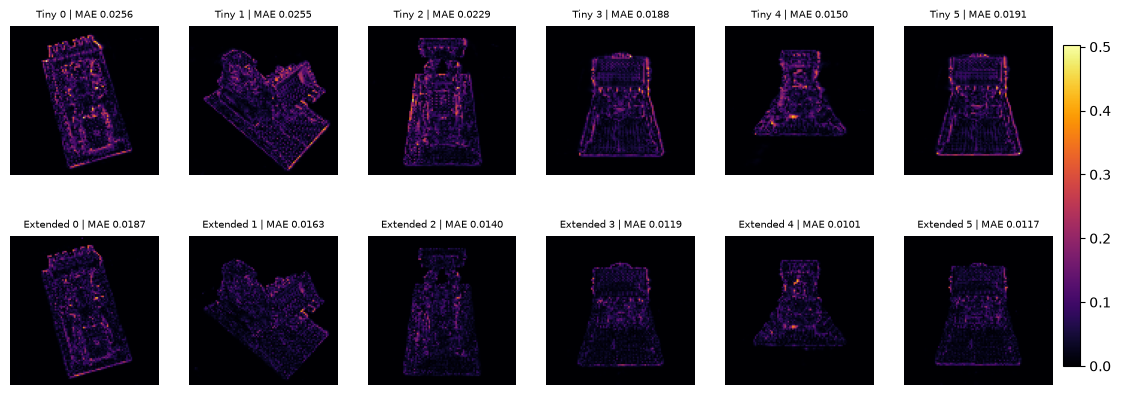

In [13]:
fig, axes = plt.subplots(2, len(test_images), figsize=(2.3*len(test_images), 5))
vmax = 0.
for i in range(len(test_images)):
    gt = test_images[i].cpu().numpy()
    vmax = max(vmax, np.abs(results['Tiny NeRF'][0][i] - gt).mean(-1).max())

for i in range(len(test_images)):
    gt = test_images[i].cpu().numpy()
    for r, name in enumerate(['Tiny NeRF', 'Extended NeRF']):
        err = np.abs(results[name][0][i] - gt).mean(-1)
        im = axes[r, i].imshow(err, cmap='inferno', vmin=0, vmax=vmax)
        axes[r, i].set_title(f'{name.split()[0]} {i} | MAE {err.mean():.4f}', fontsize=7)
        axes[r, i].axis('off')

fig.colorbar(im, ax=axes, fraction=0.015, pad=0.01)
plt.show()

## 8. Novel view synthesis

Camera poses on a sphere around the object, at angles that appear in **neither** the training nor
the test set. The spherical pose helpers are the ones provided in Tutorial 10.4; fixed angles are
used instead of the interactive sliders so this notebook reproduces the same figure every run.

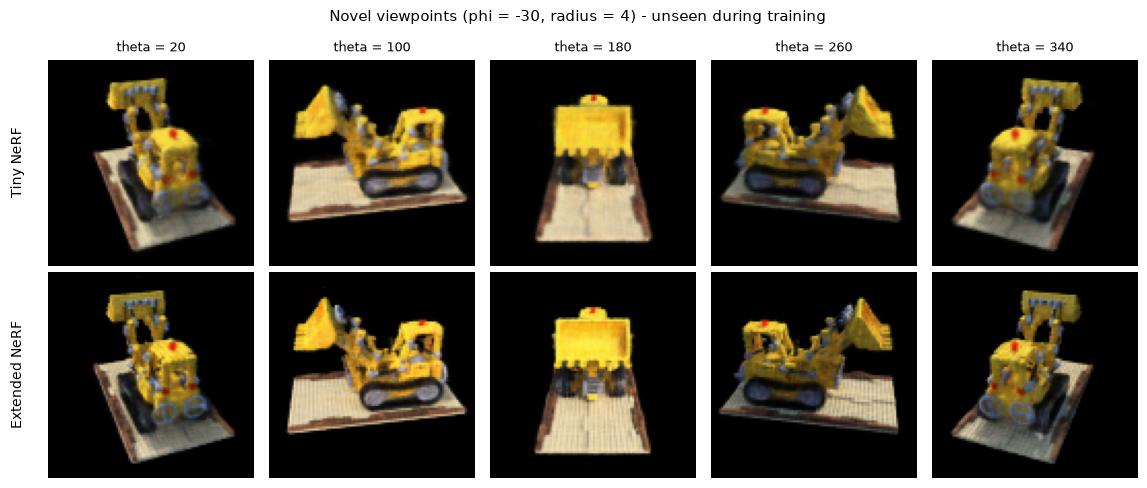

In [14]:
trans_t = lambda t: torch.tensor([
    [1, 0, 0, 0],
    [0, 1, 0, 0],
    [0, 0, 1, t],
    [0, 0, 0, 1],
], dtype=torch.float32)

rot_phi = lambda phi: torch.tensor([
    [1, 0, 0, 0],
    [0, torch.cos(phi), -torch.sin(phi), 0],
    [0, torch.sin(phi),  torch.cos(phi), 0],
    [0, 0, 0, 1],
], dtype=torch.float32)

rot_theta = lambda th: torch.tensor([
    [torch.cos(th), 0, -torch.sin(th), 0],
    [0, 1, 0, 0],
    [torch.sin(th), 0,  torch.cos(th), 0],
    [0, 0, 0, 1],
], dtype=torch.float32)

def pose_spherical(theta, phi, radius):
    c2w = trans_t(radius)
    c2w = rot_phi(torch.tensor(phi / 180. * np.pi)) @ c2w
    c2w = rot_theta(torch.tensor(theta / 180. * np.pi)) @ c2w
    c2w = torch.tensor([
        [-1, 0, 0, 0],
        [ 0, 0, 1, 0],
        [ 0, 1, 0, 0],
        [ 0, 0, 0, 1],
    ], dtype=torch.float32) @ c2w
    return c2w.to(device)


@torch.no_grad()
def render_novel(theta, phi=-30., radius=4.):
    c2w = pose_spherical(theta, phi, radius)
    rays_o, rays_d = get_rays(K, c2w[:3, :4], H, W)
    rgb_t = render_image_tiny(rays_o, rays_d)
    rgb_e = render_image_extended(rays_o, rays_d)
    return rgb_t.clamp(0, 1).cpu().numpy(), rgb_e.clamp(0, 1).cpu().numpy()


thetas = [20., 100., 180., 260., 340.]
fig, axes = plt.subplots(2, len(thetas), figsize=(2.3*len(thetas), 5))
for c, th in enumerate(thetas):
    img_t, img_e = render_novel(th)
    axes[0, c].imshow(img_t); axes[0, c].set_title(f'theta = {th:.0f}', fontsize=9)
    axes[1, c].imshow(img_e)
    axes[0, c].axis('off'); axes[1, c].axis('off')

for r, label in enumerate(['Tiny NeRF', 'Extended NeRF']):
    axes[r, 0].text(-0.15, 0.5, label, transform=axes[r, 0].transAxes,
                    rotation=90, va='center', ha='center', fontsize=10)

plt.suptitle('Novel viewpoints (phi = -30, radius = 4) - unseen during training', fontsize=11)
plt.tight_layout(); plt.show()

## 9. Isolating the view-dependent component (Task 1)

The Extended NeRF predicts colour from `(geometric feature, view direction)` while density is
predicted from position alone. To show that the colour head really does use the direction input,
the same test view is rendered twice:

1. with the **true** per-ray view directions, and
2. with every view direction **replaced by a single fixed direction** (the ray direction at the
   centre of a different camera).

The geometry is identical in both renders because density never sees the direction, so any
difference between the two images is purely the view-dependent part of the appearance. A matte
model such as Tiny NeRF would produce a difference of exactly zero.

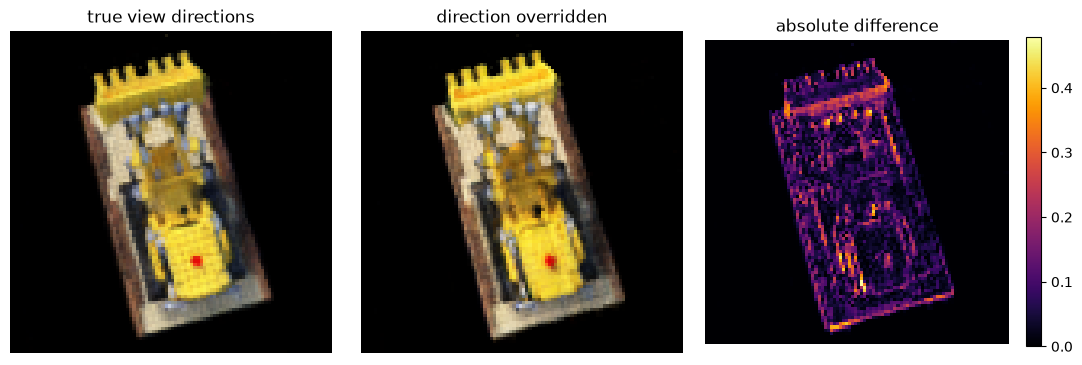

mean |difference| : 0.031893
max  |difference| : 0.478349
A non-zero difference confirms the colour head is conditioned on the view direction,
while the unchanged silhouette confirms density is not.


In [15]:
view_idx = 0
rays_o, rays_d = get_rays(K, test_poses[view_idx], H, W)

# A single fixed direction taken from a different camera, used to override the true directions
other = test_poses[3]
fixed_dir = -other[:3, 2]
fixed_dir = (fixed_dir / fixed_dir.norm()).view(1, 3)

rgb_true  = render_image_extended(rays_o, rays_d)
rgb_fixed = render_image_extended(rays_o, rays_d, dir_override=fixed_dir)

a = rgb_true.clamp(0, 1).cpu().numpy()
b = rgb_fixed.clamp(0, 1).cpu().numpy()
d = np.abs(a - b).mean(-1)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
axes[0].imshow(a); axes[0].set_title('true view directions')
axes[1].imshow(b); axes[1].set_title('direction overridden')
im = axes[2].imshow(d, cmap='inferno'); axes[2].set_title('absolute difference')
for ax in axes: ax.axis('off')
fig.colorbar(im, ax=axes[2], fraction=0.046)
plt.tight_layout(); plt.show()

print(f"mean |difference| : {d.mean():.6f}")
print(f"max  |difference| : {d.max():.6f}")
print("A non-zero difference confirms the colour head is conditioned on the view direction,")
print("while the unchanged silhouette confirms density is not.")

## 10. Summary of results

In [16]:
print("=" * 62)
print("IFN680 Project 8 - Task 3 summary")
print("=" * 62)
print(f"{'':<34}{'Tiny NeRF':>13}{'Extended':>13}")
print("-" * 62)
print(f"{'View-dependent colour':<34}{'no':>13}{'yes':>13}")
print(f"{'Sampling':<34}{'uniform':>13}{'hierarchical':>13}")
print(f"{'Network evaluations per ray':<34}{N_SAMPLES:>13}{N_C + (N_C + N_F):>13}")
print(f"{'Trainable parameters':<34}{n_tiny:>13,}{n_ext:>13,}")
print(f"{'Training epochs':<34}{len(curves_tiny['train']):>13}{len(curves_ext['train']):>13}")
print("-" * 62)
print(f"{'Mean test PSNR (dB)':<34}{np.mean(psnr_tiny):>13.2f}{np.mean(psnr_ext):>13.2f}")
print(f"{'Best / worst view (dB)':<34}"
      f"{str(round(max(psnr_tiny),1))+' / '+str(round(min(psnr_tiny),1)):>13}"
      f"{str(round(max(psnr_ext),1))+' / '+str(round(min(psnr_ext),1)):>13}")
print("-" * 62)
print(f"{'Improvement (dB)':<34}{'':>13}{np.mean(psnr_ext)-np.mean(psnr_tiny):>13.2f}")
print("=" * 62)

IFN680 Project 8 - Task 3 summary
                                      Tiny NeRF     Extended
--------------------------------------------------------------
View-dependent colour                        no          yes
Sampling                                uniform hierarchical
Network evaluations per ray                  64          128
Trainable parameters                     22,148       96,904
Training epochs                             100          100
--------------------------------------------------------------
Mean test PSNR (dB)                       25.68        29.17
Best / worst view (dB)              27.1 / 24.2  30.3 / 26.8
--------------------------------------------------------------
Improvement (dB)                                        3.49
